# COMP 9170 Data Science Project: Predicting 30-Day Hospital Readmission in Patients with Diabetes

##### December 3, 2026
##### Aneet Kaur A0
##### Paul Moolan A01513013
##### Siddharth Sudhir A0

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import seaborn as sns

#Used to format tables
from prettytable import PrettyTable

from sklearn.manifold import TSNE
from sklearn.decomposition import PCA

from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.base import clone

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

##### Insert Brief Data Introduction (Prob take from report) TODO

The dataset represents ten years (1999-2008) of clinical care at 130 US hospitals and integrated delivery networks. It includes over 50 features representing patient and hospital outcomes. Information was extracted from the database for encounters that satisfied the following criteria.

(1)	It is an inpatient encounter (a hospital admission).

(2)	It is a diabetic encounter, that is, one during which any kind of diabetes was entered into the system as a diagnosis.

(3)	The length of stay was at least 1 day and at most 14 days.

(4)	Laboratory tests were performed during the encounter.

(5)	Medications were administered during the encounter.

Data Source: https://archive.ics.uci.edu/dataset/296/diabetes+130-us+hospitals+for+years+1999-2008, Accessed: Nov 5/26

Reference Study: Strack, Beata, DeShazo, Jonathan P., Gennings, Chris, Olmo, Juan L., Ventura, Sebastian, Cios, Krzysztof J., Clore, John N., Impact of HbA1c Measurement on Hospital Readmission Rates: Analysis of 70,000 Clinical Database Patient Records, BioMed Research International, 2014, 781670, 11 pages, 2014. https://doi.org/10.1155/2014/781670

In [4]:
dbts1 = pd.read_csv('./data/diabetic_data.csv')

# dbts1 = pd.read_csv('/content/diabetic_data.csv')

## Exploratory Data Analysis

In [5]:
data = dbts1.copy()

display(data.info(), data.describe())

<class 'pandas.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype
---  ------                    --------------   -----
 0   encounter_id              101766 non-null  int64
 1   patient_nbr               101766 non-null  int64
 2   race                      101766 non-null  str  
 3   gender                    101766 non-null  str  
 4   age                       101766 non-null  str  
 5   weight                    101766 non-null  str  
 6   admission_type_id         101766 non-null  int64
 7   discharge_disposition_id  101766 non-null  int64
 8   admission_source_id       101766 non-null  int64
 9   time_in_hospital          101766 non-null  int64
 10  payer_code                101766 non-null  str  
 11  medical_specialty         101766 non-null  str  
 12  num_lab_procedures        101766 non-null  int64
 13  num_procedures            101766 non-null  int64
 14  num_medications           10176

None

,encounter_id,patient_nbr,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses
count,1.017660e+05,1.017660e+05,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000
mean,1.652016e+08,5.433040e+07,2.024006,3.715642,5.754437,4.395987,43.095641,1.339730,16.021844,0.369357,0.197836,0.635566,7.422607
std,1.026403e+08,3.869636e+07,1.445403,5.280166,4.064081,2.985108,19.674362,1.705807,8.127566,1.267265,0.930472,1.262863,1.933600
min,1.252200e+04,1.350000e+02,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000
25%,8.496119e+07,2.341322e+07,1.000000,1.000000,1.000000,2.000000,31.000000,0.000000,10.000000,0.000000,0.000000,0.000000,6.000000
50%,1.523890e+08,4.550514e+07,1.000000,1.000000,7.000000,4.000000,44.000000,1.000000,15.000000,0.000000,0.000000,0.000000,8.000000
75%,2.302709e+08,8.754595e+07,3.000000,4.000000,7.000000,6.000000,57.000000,2.000000,20.000000,0.000000,0.000000,1.000000,9.000000
max,4.438672e+08,1.895026e+08,8.000000,28.000000,25.000000,14.000000,132.000000,6.000000,81.000000,42.000000,76.000000,21.000000,16.000000


Taken from the UCI data source: https://archive.ics.uci.edu/dataset/296/diabetes+130-us+hospitals+for+years+1999-2008

| Variable Name | Role | Type | Demographic | Description |
|---|---|---|---|---|
| encounter\_id | ID | | | Unique identifier of an encounter |
| patient\_nbr | ID | | | Unique identifier of a patient |
| race | Feature | Categorical | Race | Values: Caucasian, Asian, African American, Hispanic, and other |
| gender | Feature | Categorical | Gender | Values: male, female, and unknown/invalid |
| age | Feature | Categorical | Age | Grouped in 10-year intervals: [0, 10), [10, 20), ..., [90, 100) |
| weight | Feature | Categorical | | Weight in pounds. |
| admission\_type\_id | Feature | Categorical | | Integer identifier corresponding to 9 distinct values, for example, emergency, urgent, elective, newborn, and not available |
| discharge\_disposition\_id | Feature | Categorical | | Integer identifier corresponding to 29 distinct values, for example, discharged to home, expired, and not available |
| admission\_source\_id | Feature | Categorical | | Integer identifier corresponding to 21 distinct values, for example, physician referral, emergency room, and transfer from a hospital |
| time\_in\_hospital | Feature | Integer | | Integer number of days between admission and discharge |
| payer\_code | Feature | Categorical | | Integer identifier corresponding to 23 distinct values, for example, Blue Cross/Blue Shield, Medicare, and self-pay |
| medical\_specialty | Feature | Categorical | | Integer identifier of a specialty of the admitting physician, corresponding to 84 distinct values, for example, cardiology, internal medicine, family/general practice, and surgeon |
| num\_lab\_procedures | Feature | Integer | | Number of lab tests performed during the encounter |
| num\_procedures | Feature | Integer | | Number of procedures (other than lab tests) performed during the encounter |
| num\_medications | Feature | Integer | | Number of distinct generic names administered during the encounter |
| number\_outpatient | Feature | Integer | | Number of outpatient visits of the patient in the year preceding the encounter |
| number\_emergency | Feature | Integer | | Number of emergency visits of the patient in the year preceding the encounter |
| number\_inpatient | Feature | Integer | | Number of inpatient visits of the patient in the year preceding the encounter |
| diag\_1 | Feature | Categorical | | The primary diagnosis (coded as first three digits of ICD9); 848 distinct values |
| diag\_2 | Feature | Categorical | | Secondary diagnosis (coded as first three digits of ICD9); 923 distinct values |
| diag\_3 | Feature | Categorical | | Additional secondary diagnosis (coded as first three digits of ICD9); 954 distinct values |
| number\_diagnoses | Feature | Integer | | Number of diagnoses entered to the system |
| max\_glu\_serum | Feature | Categorical | | Indicates the range of the result or if the test was not taken. Values: \>200, \>300, normal, and none if not measured |
| A1Cresult | Feature | Categorical | | Indicates the range of the result or if the test was not taken. Values: \>8 if the result was greater than 8%, \>7 if the result was greater than 7% but less than 8%, normal if the result was less than 7%, and none if not measured. |
| metformin | Feature | Categorical | | The feature indicates whether the drug was prescribed or there was a change in the dosage. Values: up if the dosage was increased during the encounter, down if the dosage was decreased, steady if the dosage did not change, and no if the drug was not prescribed |
| repaglinide | Feature | Categorical | | The feature indicates whether the drug was prescribed or there was a change in the dosage. Values: up if the dosage was increased during the encounter, down if the dosage was decreased, steady if the dosage did not change, and no if the drug was not prescribed |
| nateglinide | Feature | Categorical | | The feature indicates whether the drug was prescribed or there was a change in the dosage. Values: up if the dosage was increased during the encounter, down if the dosage was decreased, steady if the dosage did not change, and no if the drug was not prescribed |
| chlorpropamide | Feature | Categorical | | The feature indicates whether the drug was prescribed or there was a change in the dosage. Values: up if the dosage was increased during the encounter, down if the dosage was decreased, steady if the dosage did not change, and no if the drug was not prescribed |
| glimepiride | Feature | Categorical | | The feature indicates whether the drug was prescribed or there was a change in the dosage. Values: up if the dosage was increased during the encounter, down if the dosage was decreased, steady if the dosage did not change, and no if the drug was not prescribed |
| acetohexamide | Feature | Categorical | | The feature indicates whether the drug was prescribed or there was a change in the dosage. Values: up if the dosage was increased during the encounter, down if the dosage was decreased, steady if the dosage did not change, and no if the drug was not prescribed |
| glipizide | Feature | Categorical | | The feature indicates whether the drug was prescribed or there was a change in the dosage. Values: up if the dosage was increased during the encounter, down if the dosage was decreased, steady if the dosage did not change, and no if the drug was not prescribed |
| glyburide | Feature | Categorical | | The feature indicates whether the drug was prescribed or there was a change in the dosage. Values: up if the dosage was increased during the encounter, down if the dosage was decreased, steady if the dosage did not change, and no if the drug was not prescribed |
| tolbutamide | Feature | Categorical | | The feature indicates whether the drug was prescribed or there was a change in the dosage. Values: up if the dosage was increased during the encounter, down if the dosage was decreased, steady if the dosage did not change, and no if the drug was not prescribed |
| pioglitazone | Feature | Categorical | | The feature indicates whether the drug was prescribed or there was a change in the dosage. Values: up if the dosage was increased during the encounter, down if the dosage was decreased, steady if the dosage did not change, and no if the drug was not prescribed |
| rosiglitazone | Feature | Categorical | | The feature indicates whether the drug was prescribed or there was a change in the dosage. Values: up if the dosage was increased during the encounter, down if the dosage was decreased, steady if the dosage did not change, and no if the drug was not prescribed |
| acarbose | Feature | Categorical | | The feature indicates whether the drug was prescribed or there was a change in the dosage. Values: up if the dosage was increased during the encounter, down if the dosage was decreased, steady if the dosage did not change, and no if the drug was not prescribed |
| miglitol | Feature | Categorical | | The feature indicates whether the drug was prescribed or there was a change in the dosage. Values: up if the dosage was increased during the encounter, down if the dosage was decreased, steady if the dosage did not change, and no if the drug was not prescribed |
| troglitazone | Feature | Categorical | | The feature indicates whether the drug was prescribed or there was a change in the dosage. Values: up if the dosage was increased during the encounter, down if the dosage was decreased, steady if the dosage did not change, and no if the drug was not prescribed |
| tolazamide | Feature | Categorical | | The feature indicates whether the drug was prescribed or there was a change in the dosage. Values: up if the dosage was increased during the encounter, down if the dosage was decreased, steady if the dosage did not change, and no if the drug was not prescribed |
| examide | Feature | Categorical | | The feature indicates whether the drug was prescribed or there was a change in the dosage. Values: up if the dosage was increased during the encounter, down if the dosage was decreased, steady if the dosage did not change, and no if the drug was not prescribed |
| citoglipton | Feature | Categorical | | The feature indicates whether the drug was prescribed or there was a change in the dosage. Values: up if the dosage was increased during the encounter, down if the dosage was decreased, steady if the dosage did not change, and no if the drug was not prescribed |
| insulin | Feature | Categorical | | The feature indicates whether the drug was prescribed or there was a change in the dosage. Values: up if the dosage was increased during the encounter, down if the dosage was decreased, steady if the dosage did not change, and no if the drug was not prescribed |
| glyburide-metformin | Feature | Categorical | | The feature indicates whether the drug was prescribed or there was a change in the dosage. Values: up if the dosage was increased during the encounter, down if the dosage was decreased, steady if the dosage did not change, and no if the drug was not prescribed |
| glipizide-metformin | Feature | Categorical | | The feature indicates whether the drug was prescribed or there was a change in the dosage. Values: up if the dosage was increased during the encounter, down if the dosage was decreased, steady if the dosage did not change, and no if the drug was not prescribed |
| glimepiride-pioglitazone | Feature | Categorical | | The feature indicates whether the drug was prescribed or there was a change in the dosage. Values: up if the dosage was increased during the encounter, down if the dosage was decreased, steady if the dosage did not change, and no if the drug was not prescribed |
| metformin-rosiglitazone | Feature | Categorical | | The feature indicates whether the drug was prescribed or there was a change in the dosage. Values: up if the dosage was increased during the encounter, down if the dosage was decreased, steady if the dosage did not change, and no if the drug was not prescribed |
| metformin-pioglitazone | Feature | Categorical | | The feature indicates whether the drug was prescribed or there was a change in the dosage. Values: up if the dosage was increased during the encounter, down if the dosage was decreased, steady if the dosage did not change, and no if the drug was not prescribed |
| change | Feature | Categorical | | Indicates if there was a change in diabetic medications (either dosage or generic name). Values: change and no change |
| diabetesMed | Feature | Categorical | | Indicates if there was any diabetic medication prescribed. Values: yes and no |
| readmitted | Target | Categorical | | Days to inpatient readmission. Values: \<30 if the patient was readmitted in less than 30 days, \>30 if the patient was readmitted in more than 30 days, and No for no record of readmission. |

In [6]:
# Sample rows and data shape.
display(data.shape,data.head())

(101766, 50)

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


### Sorting features by type


TODO: Short explanation of groupings, and how each feature type will need to be processed prior to modeling

In [7]:
# target = 'readmitted'

#Identifier columns.
identifiers = ['encounter_id', 'patient_nbr']

ratio_features = [
    'time_in_hospital',
    'num_lab_procedures',
    'num_procedures',
    'num_medications',
    'number_outpatient',
    'number_emergency',
    'number_inpatient',
    'number_diagnoses'
]

#One hot encoding for nominal and ordinal features

categorical_features = [
    'gender',
    'race',
    'diabetesMed',
    'change',
    'admission_type_id', 
    'discharge_disposition_id', 
    'admission_source_id',
    'payer_code', 
    'medical_specialty',
    'diag_1', 
    'diag_2', 
    'diag_3'
]

# ['No','Down','Steady','Up'] for the ordinal data. Except age and weight which are binned values.
ordinal_features =  [
    'max_glu_serum',
    'A1Cresult',
    'weight',
    'age',
    'metformin', 
    'repaglinide', 
    'nateglinide', 
    'chlorpropamide',
    'pioglitazone', 
    'rosiglitazone', 
    'acarbose', 
    'miglitol', 
    'troglitazone',
    'glimepiride', 
    'acetohexamide', 
    'glipizide', 
    'glyburide', 
    'tolbutamide',
    'tolazamide', 
    'examide', 
    'citoglipton', 
    'insulin',
    'glyburide-metformin', 
    'glipizide-metformin',
    'glimepiride-pioglitazone', 
    'metformin-rosiglitazone',
    'metformin-pioglitazone'
]

### Demographic and Target(Readmission) Distributions

readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64


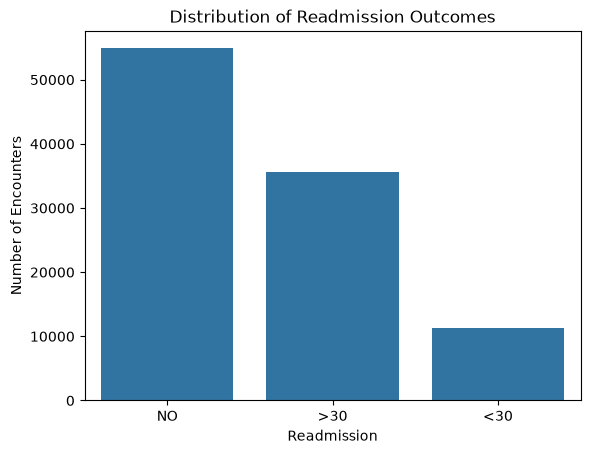

In [8]:
print(data['readmitted'].value_counts())

sns.countplot(data=data, x='readmitted')

plt.title('Distribution of Readmission Outcomes')
plt.xlabel('Readmission')
plt.ylabel('Number of Encounters')
plt.show()

race
Caucasian          76099
AfricanAmerican    19210
?                   2273
Hispanic            2037
Other               1506
Asian                641
Name: count, dtype: int64


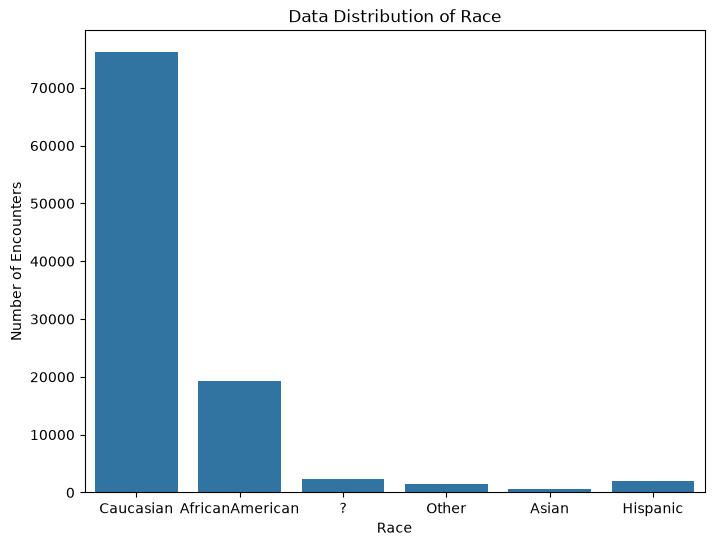

In [9]:
print(data['race'].value_counts())

plt.figure(figsize=(8, 6))
sns.countplot(data=data, x='race')

plt.title('Data Distribution of Race')
plt.xlabel('Race')
plt.ylabel('Number of Encounters')
plt.show()

gender
Female             54708
Male               47055
Unknown/Invalid        3
Name: count, dtype: int64


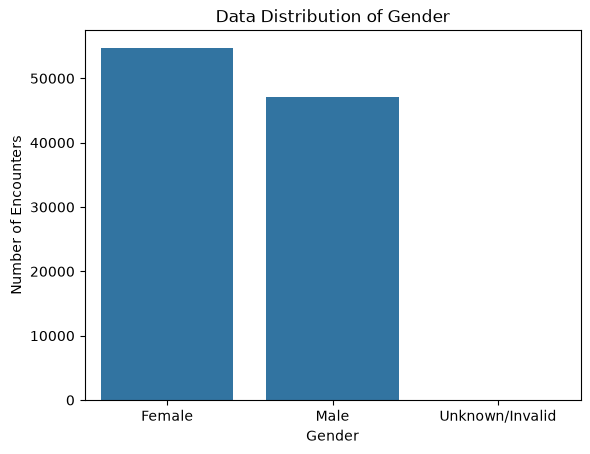

In [10]:
print(data['gender'].value_counts())

sns.countplot(data=data, x='gender')

plt.title('Data Distribution of Gender')
plt.xlabel('Gender')
plt.ylabel('Number of Encounters')
plt.show()

age
[70-80)     26068
[60-70)     22483
[50-60)     17256
[80-90)     17197
[40-50)      9685
[30-40)      3775
[90-100)     2793
[20-30)      1657
[10-20)       691
[0-10)        161
Name: count, dtype: int64


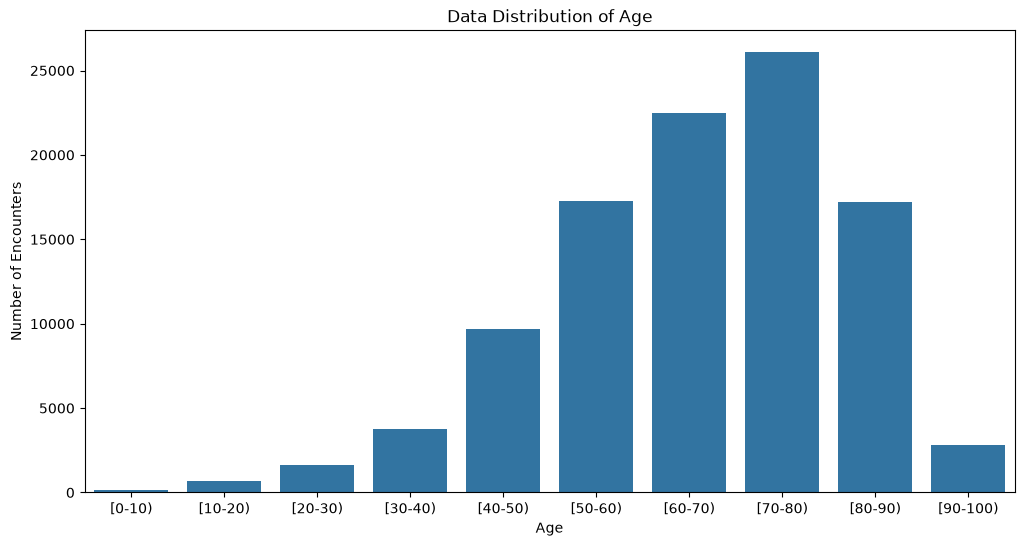

In [11]:
print(data['age'].value_counts())

plt.figure(figsize=(12, 6))
sns.countplot(data=data, x='age')

plt.title('Data Distribution of Age')
plt.xlabel('Age')
plt.ylabel('Number of Encounters')
plt.show()

### Missing Values and Duplicate Analysis

In [12]:
# The dataset uses ? for missing values, 'Unknown/Invalid' for gender. Keeping missing categories for now.
data.replace(['?','Unknown/Invalid'], np.nan, inplace=True)

missing = pd.DataFrame({
    'Count': data.isnull().sum(),
    'Percentage': data.isnull().mean() * 100
})

missing = missing[missing['Count'] > 0]
missing.sort_values('Percentage', ascending=False)

,Count,Percentage
weight,98569,96.858479
max_glu_serum,96420,94.746772
A1Cresult,84748,83.277322
medical_specialty,49949,49.082208
payer_code,40256,39.557416
race,2273,2.233555
diag_3,1423,1.398306
diag_2,358,0.351787
diag_1,21,0.020636
gender,3,0.002948


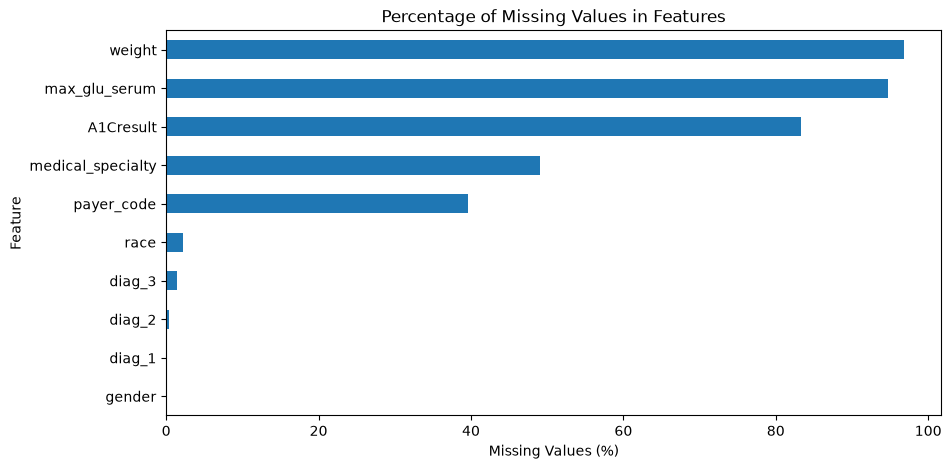

In [13]:
missing['Percentage'].sort_values().plot(
    kind='barh',
    figsize=(10, 5)
)

plt.title('Percentage of Missing Values in Features')
plt.xlabel('Missing Values (%)')
plt.ylabel('Feature')
plt.show()

In [14]:
print('Duplicate rows:', data.duplicated().sum())

data = data.drop_duplicates()

Duplicate rows: 0


In [15]:
print('Unique encounters:', data['encounter_id'].nunique())
print('Unique patients:', data['patient_nbr'].nunique())

Unique encounters: 101766
Unique patients: 71518


## Data Imputation and Filtering

| Column | Count | Percentage | Treatment
|---|---:|---:| ---:|
| weight | 98569 | 96.858479 | Drop feature|
| max_glu_serum | 96420 | 94.746772 |Drop feature|
| A1Cresult | 84748 | 83.277322 |Drop feature|
| medical_specialty | 49949 | 49.082208 |Impute NaN as Unknown|
| payer_code | 40256 | 39.557416 |Impute NaN as Unknown|
| race | 2273 | 2.233555 |Drop rows|
| diag_3 | 1423 | 1.398306 |Drop rows|
| diag_2 | 358 | 0.351787 |Drop rows|
| diag_1 | 21 | 0.020636 |Drop rows|
| gender | 3 | 0.002948 |Drop rows|

Based on the table above, we decided to ignore weight, max_glu_serum, A1Cresult for predictor columns, since they are more than or close to half empty. For payer_code, this is potentially important, since someone who does not have insurance may be more reticent to come back for readmission. For medical_specialty this may be important, ie where does a patient get assigned by the hospital may carry info.


    medical_specialty - Integer identifier of a specialty of the admitting physician, corresponding to 84 distinct values, for example, cardiology, internal medicine, family/general practice, and surgeon
    
    payer_code - Integer identifier corresponding to 23 distinct values, for example, Blue Cross/Blue Shield, Medicare, and self-pay

For payer_code and medical_specialty impute nan into an "Unknown" category, since this may still be informative.


In [16]:
# Only readmissions in less than 30 days count as a positive outcome.
data = data.dropna(subset=['readmitted', 'patient_nbr'])

data['readmitted_30'] = (
    data['readmitted'] == '<30'
).astype(int)

display(data['readmitted_30'].value_counts())
print()
display(data['readmitted_30'].value_counts(normalize=True) * 100)

readmitted_30
0    90409
1    11357
Name: count, dtype: int64

readmitted_30
0    88.840084
1    11.159916
Name: proportion, dtype: float64

In [17]:
# Filter out columns with more than 50% missing values.
excluded_empty_features = ['max_glu_serum','A1Cresult','weight']
ordinal_features = [i for i in ordinal_features if i not in excluded_empty_features]
categorical_features = [i for i in categorical_features if i not in excluded_empty_features]
ratio_features = [i for i in ratio_features if i not in excluded_empty_features]

# Remove nan rows for the below columns since there are relatively few empty rows.
remove_nan_rows = ['race', 'diag_3', 'diag_2' , 'diag_1' , 'gender']
data = data.dropna(subset=remove_nan_rows)

# For payer_code and medical_specialty fill nan with unknown category
data['payer_code'] = data['payer_code'].fillna('Unknown')
data['medical_specialty'] = data['medical_specialty'].fillna('Unknown')

In [18]:
#Note Claude 5.5 was used to help format the table outputs here.

# Ratio summary
t = PrettyTable(["Ratio Feature", "Count","Min", "Max", "Mean", "Median", "Stdev"])
stats = data[ratio_features].agg(["count","min", "max", "mean", "median", "std"]).T

for col, row in stats.iterrows():
    t.add_row([col] + [np.round(v,3) for v in row])

print(t)

# Ordinal summary
t = PrettyTable(["Ordinal Feature", "# Unique", "# Missing", "Values"])

for col in ordinal_features:
    uniques = data[col].unique()
    shown = ", ".join(map(str, uniques[:4]))
    if len(uniques) > 4:
        shown += f", ... (+{len(uniques) - 4} more)"
    t.add_row([col, len(uniques), data[col].isna().sum(), shown])

print(t)

# Categorical summary
t = PrettyTable(["Categorical Feature", "# Unique", "# Missing", "Values"])

for col in categorical_features:
    uniques = data[col].unique()

    if(col == 'medical_specialty'):
        shown = ", ".join(map(str, uniques[:3]))
    else:
        shown = ", ".join(map(str, uniques[:8]))
    
    if len(uniques) > 8:
        if(col == 'medical_specialty'):
            shown += f", ... (+{len(uniques) - 3} more)"
        else:
            shown += f", ... (+{len(uniques) - 8} more)"
            
    t.add_row([col, len(uniques), data[col].isna().sum(), shown])

print(t)

+--------------------+---------+-----+-------+--------+--------+--------+
|   Ratio Feature    |  Count  | Min |  Max  |  Mean  | Median | Stdev  |
+--------------------+---------+-----+-------+--------+--------+--------+
|  time_in_hospital  | 98052.0 | 1.0 |  14.0 | 4.422  |  4.0   | 2.993  |
| num_lab_procedures | 98052.0 | 1.0 | 132.0 | 43.148 |  44.0  | 19.712 |
|   num_procedures   | 98052.0 | 0.0 |  6.0  | 1.351  |  1.0   | 1.708  |
|  num_medications   | 98052.0 | 1.0 |  81.0 | 16.12  |  15.0  | 8.108  |
| number_outpatient  | 98052.0 | 0.0 |  42.0 | 0.376  |  0.0   | 1.283  |
|  number_emergency  | 98052.0 | 0.0 |  76.0 | 0.202  |  0.0   | 0.943  |
|  number_inpatient  | 98052.0 | 0.0 |  21.0 | 0.647  |  0.0   | 1.271  |
|  number_diagnoses  | 98052.0 | 3.0 |  16.0 | 7.512  |  8.0   | 1.832  |
+--------------------+---------+-----+-------+--------+--------+--------+
+--------------------------+----------+-----------+---------------------------------------------------+
|     Or

In [19]:
# Note in the above table that ordinal: metformin-rosiglitazone, citoglipton, and examide only have 1 unique value,
# ie useless for prediction, constant feature. Hence drop these columns

drop_constant_features = ['metformin-rosiglitazone','citoglipton','examide']
ordinal_features = [i for i in ordinal_features if i not in drop_constant_features]

print(ratio_features,'\n\n',ordinal_features,'\n\n',categorical_features,'\n')

print(len(ratio_features)+len(categorical_features)+len(ordinal_features),"non-trivial features.")

['time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses'] 

 ['age', 'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'tolazamide', 'insulin', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-pioglitazone'] 

 ['gender', 'race', 'diabetesMed', 'change', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'payer_code', 'medical_specialty', 'diag_1', 'diag_2', 'diag_3'] 

41 non-trivial features.


## Feature Ranking

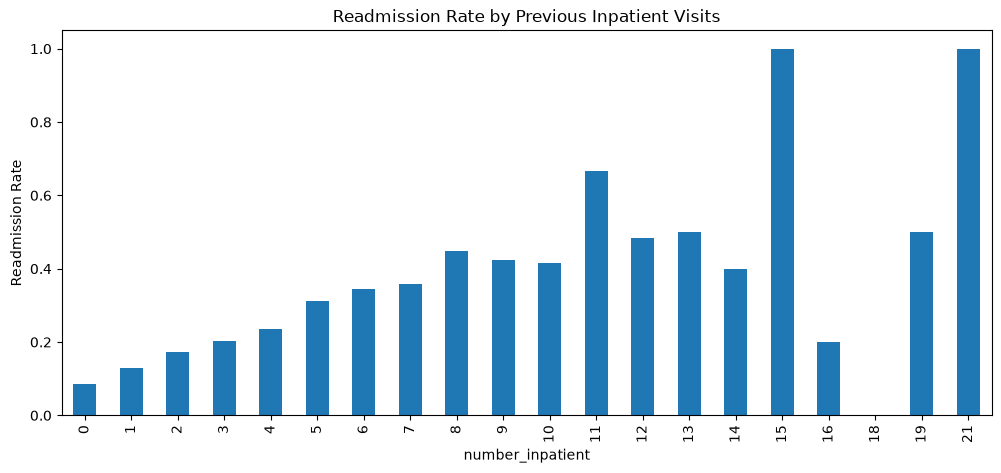

In [20]:
# Looking at previous inpatient visits as a possible predictor of readmission.
inpatient_readmission = data.groupby('number_inpatient')['readmitted_30'].mean()

inpatient_readmission.plot(kind='bar', figsize=(12, 5))

plt.title('Readmission Rate by Previous Inpatient Visits')
plt.ylabel('Readmission Rate')
plt.show()

In [ ]:
# do corr, mutual info, rfe


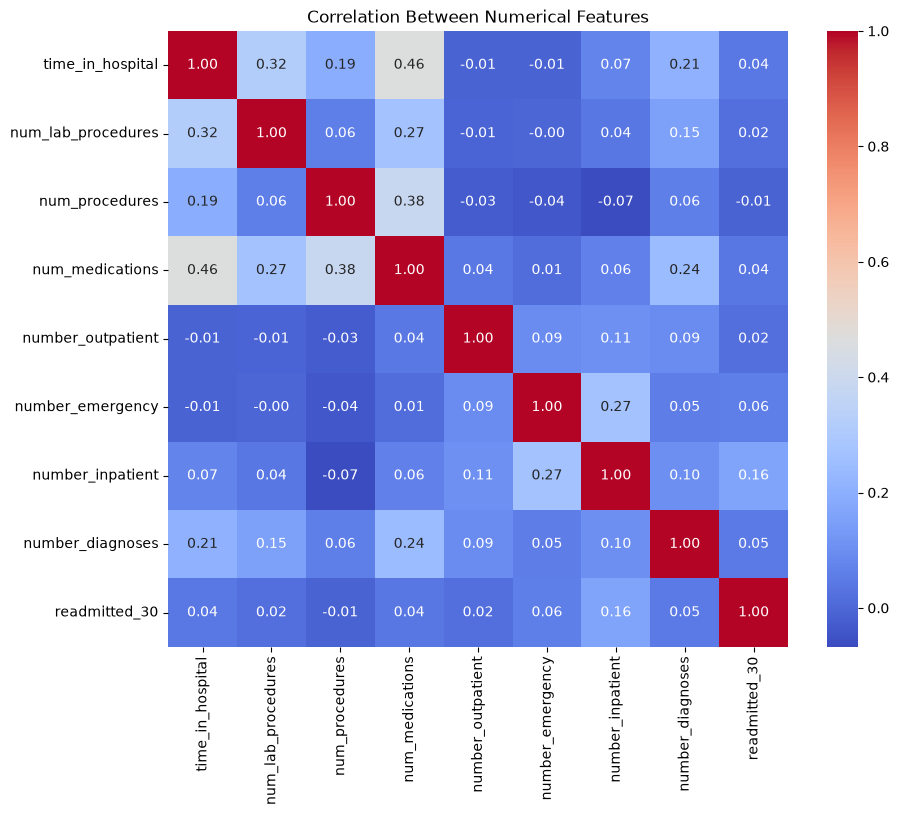

In [21]:
correlation = data[
    ratio_features + ['readmitted_30']
].corr()

plt.figure(figsize=(10, 8))

sns.heatmap(
    correlation,
    annot=True,
    fmt='.2f',
    cmap='coolwarm'
)

plt.title('Correlation Between Numerical Features')
plt.show()

## Unsupervised Clustering: t-SNE

In [22]:
print(categorical_features)
print(ordinal_features)
print(ratio_features)

['gender', 'race', 'diabetesMed', 'change', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'payer_code', 'medical_specialty', 'diag_1', 'diag_2', 'diag_3']
['age', 'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'tolazamide', 'insulin', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-pioglitazone']
['time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses']


In [23]:
# https://scikit-learn.org/stable/modules/generated/sklearn.compose.ColumnTransformer.html
# https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OrdinalEncoder.html
# https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html

df = data.copy()

# ordinal data feature ordering for OrdinalEncoder
age_order  = ['[0-10)', '[10-20)', '[20-30)', '[30-40)', '[40-50)', '[50-60)', '[60-70)', '[70-80)', '[80-90)', '[90-100)']
drug_order = ["No", "Down", "Steady", "Up"]

drug_ordinal = [i for i in ordinal_features if i != 'age']

#Scale ratio data normal, use Ordinal encoder for age and drug values, use one hot encoding for categorical features.
preprocess = ColumnTransformer([
    ("ratio", StandardScaler(), ratio_features),
    ("age", Pipeline([("enc", OrdinalEncoder(categories=[age_order])),
                      ("scale", StandardScaler())]), ["age"]),
    ("drugs", Pipeline([("enc", OrdinalEncoder(categories=[drug_order]*len(drug_ordinal))),
                        ("scale", StandardScaler())]), drug_ordinal),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_features),
])

X = preprocess.fit_transform(df)

In [24]:
# Sample X, t-SNE too slow otherwise, also pca dimensions reduction

rng = np.random.RandomState(42)
sampled = rng.choice(len(X), size=25000, replace=False)
X_sample = X[sampled]

# Dimension reduction using PCA first then t-SNE.
X_100 = PCA(n_components=100, random_state=42).fit_transform(X_sample)
tsne = TSNE(n_components=2, random_state=42)
X_tsne = tsne.fit_transform(X_100)

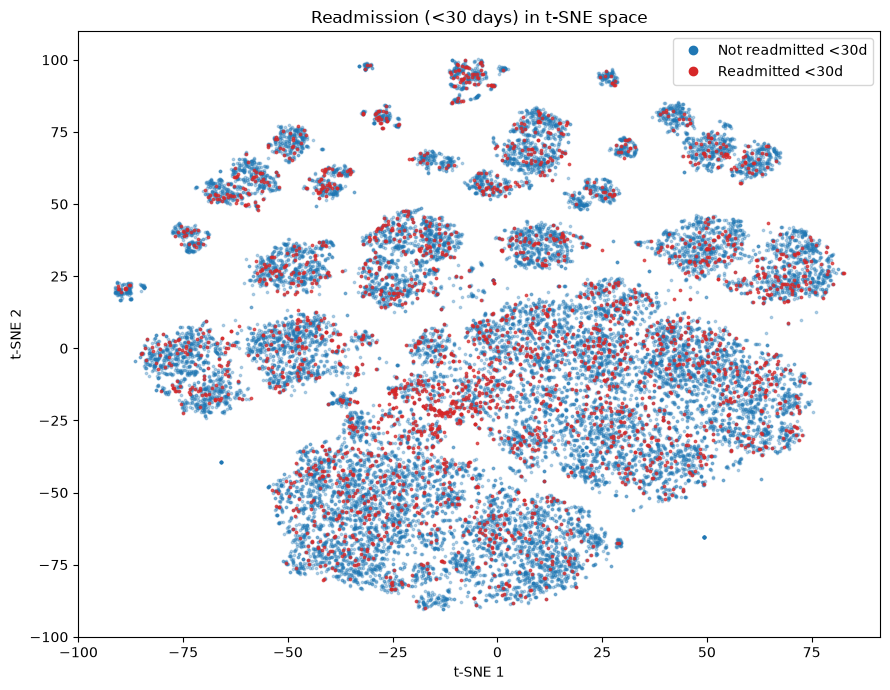

In [25]:
fig, ax = plt.subplots(figsize=(9, 7))

#  Plot the postive values on top of the neagtive ones, since they are more rare. Claude used to help format plot.
mask = df["readmitted_30"].values[sampled] == 1
ax.scatter(X_tsne[~mask, 0], X_tsne[~mask, 1], c="tab:blue", s=3, alpha=0.3, rasterized=True)
ax.scatter(X_tsne[mask, 0], X_tsne[mask, 1], c="tab:red", s=3, alpha=0.7, rasterized=True)

ax.set_xlabel("t-SNE 1")
ax.set_ylabel("t-SNE 2")
ax.set_title("Readmission (<30 days) in t-SNE space")
ax.legend(handles=[
    Line2D([0], [0], marker="o", linestyle="", color="tab:blue", label="Not readmitted <30d"),
    Line2D([0], [0], marker="o", linestyle="", color="tab:red", label="Readmitted <30d"),
], loc="best")

plt.tight_layout()
plt.show()

## Supervised Models

In [26]:
features = ratio_features + categorical_features + ordinal_features

X = data[features]
y = data['readmitted_30']
groups = data['patient_nbr']

print(X.shape)
print(y.shape)

(98052, 41)
(98052,)


In [27]:
# Split by patient rather than encounter to avoid data leakage.
# Keeping 20% of the patients aside for final testing.
split = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_val_idx, test_idx = next(
    split.split(X, y, groups)
)

X_train_val = X.iloc[train_val_idx]
y_train_val = y.iloc[train_val_idx]

X_test = X.iloc[test_idx]
y_test = y.iloc[test_idx]

In [28]:
# Roughly 60/20/20 overall split by patient. Using validation for the initial experiments.
split2 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.25,
    random_state=42
)

train_idx, val_idx = next(
    split2.split(
        X_train_val,
        y_train_val,
        groups.iloc[train_val_idx]
    )
)

X_train = X_train_val.iloc[train_idx]
y_train = y_train_val.iloc[train_idx]

X_val = X_train_val.iloc[val_idx]
y_val = y_train_val.iloc[val_idx]

In [29]:
print('Training:', X_train.shape)
print('Validation:', X_val.shape)
print('Testing:', X_test.shape)

Training: (59073, 41)
Validation: (19530, 41)
Testing: (19449, 41)


In [30]:
# ordinal data feature ordering for OrdinalEncoder
age_order  = ['[0-10)', '[10-20)', '[20-30)', '[30-40)', '[40-50)', '[50-60)', '[60-70)', '[70-80)', '[80-90)', '[90-100)']
drug_order = ["No", "Down", "Steady", "Up"]

drug_ordinal = [i for i in ordinal_features if i != 'age']

#Scale ratio data normal, use Ordinal encoder for age and drug values, use one hot encoding for categorical features.
preprocessor = ColumnTransformer([
    ("ratio", StandardScaler(), ratio_features),
    ("age", Pipeline([("enc", OrdinalEncoder(categories=[age_order])),
                      ("scale", StandardScaler())]), ["age"]),
    ("drugs", Pipeline([("enc", OrdinalEncoder(categories=[drug_order]*len(drug_ordinal))),
                        ("scale", StandardScaler())]), drug_ordinal),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_features),
])

# Updated to use ordinal encoder for ordinal features.
# preprocessor = ColumnTransformer([
#     ('num', numerical_pipeline, ratio_features),
#     ('cat', categorical_pipeline, categorical_features)
# ])

In [31]:
# Experiment 1: Dummy classifier as the baseline for the other two models.
# Kept the random forest small for the initial pipeline.
models = {
    'Dummy Classifier': DummyClassifier(
        strategy='most_frequent'
    ),

    'Logistic Regression': LogisticRegression(
        max_iter=1000
    ),

    'Random Forest': RandomForestClassifier(
        n_estimators=50,
        max_depth=10,
        random_state=42
    )
}

In [32]:
trained_models = {}

for name, model in models.items():
    pipeline = Pipeline([
        ('preprocessing', clone(preprocessor)),
        ('model', model)
    ])

    pipeline.fit(X_train, y_train)
    trained_models[name] = pipeline

    print(name, 'trained successfully')

Dummy Classifier trained successfully
Logistic Regression trained successfully
Random Forest trained successfully


In [33]:
# Using the same validation set for all models. Accuracy alone may be misleading.
results = []

for name, model in trained_models.items():
    predictions = model.predict(X_val)
    probabilities = model.predict_proba(X_val)[:, 1]

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_val, predictions),
        'Precision': precision_score(y_val, predictions, zero_division=0),
        'Recall': recall_score(y_val, predictions, zero_division=0),
        'F1 Score': f1_score(y_val, predictions, zero_division=0),
        'ROC AUC': roc_auc_score(y_val, probabilities),
        'Average Precision': average_precision_score(y_val, probabilities)
    })

results_df = pd.DataFrame(results)
results_df.round(3)

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC,Average Precision
0,Dummy Classifier,0.889,0.000,0.00,0.000,0.500,0.111
1,Logistic Regression,0.889,0.494,0.02,0.038,0.663,0.214
2,Random Forest,0.889,0.000,0.00,0.000,0.661,0.204


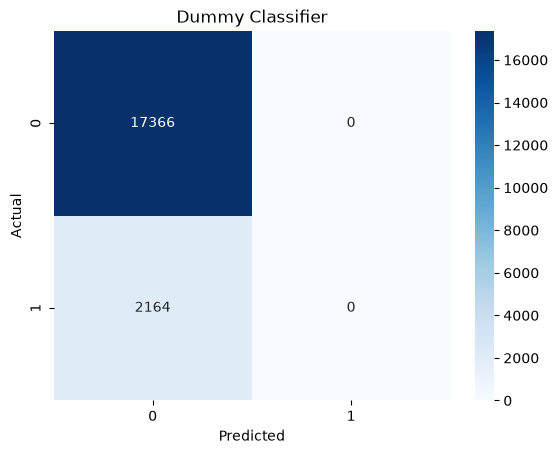

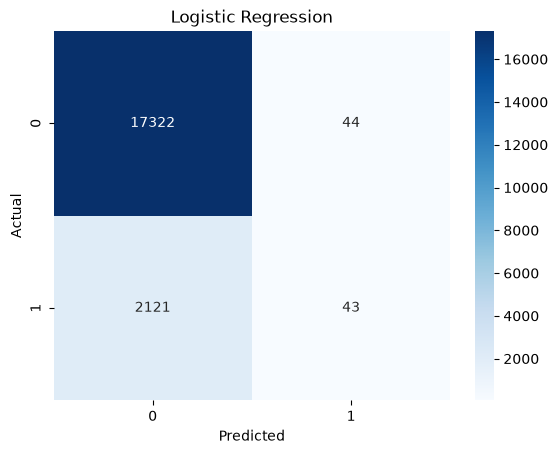

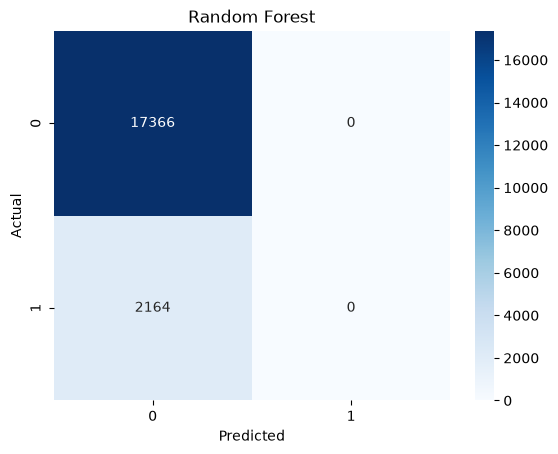

In [34]:
for name, model in trained_models.items():
    predictions = model.predict(X_val)
    cm = confusion_matrix(y_val, predictions)

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues'
    )

    plt.title(name)
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.show()

In [35]:
# Experiment 2: Using built-in feature importance for now.
# Can add SHAP/LIME later for a more detailed interpretation.
rf_pipeline = trained_models['Random Forest']
rf_model = rf_pipeline.named_steps['model']

feature_names = rf_pipeline.named_steps['preprocessing'].get_feature_names_out()

importance = pd.Series(
    rf_model.feature_importances_,
    index=feature_names
)

importance = importance.sort_values(ascending=False)
importance.head(10)

ratio__number_inpatient             0.114827
cat__discharge_disposition_id_22    0.040533
ratio__time_in_hospital             0.036115
cat__discharge_disposition_id_1     0.033614
ratio__number_emergency             0.028633
ratio__num_medications              0.026081
cat__discharge_disposition_id_11    0.024233
ratio__number_diagnoses             0.020437
ratio__num_lab_procedures           0.017973
age__age                            0.017679
dtype: float64

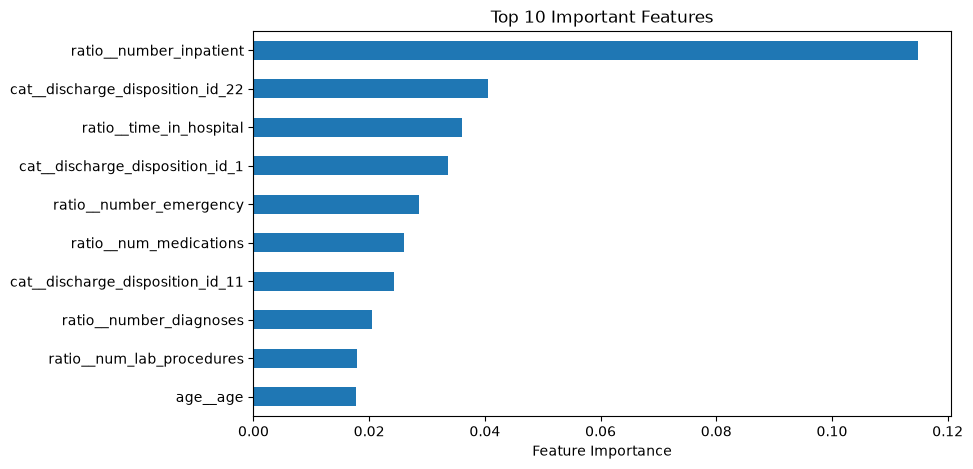

In [36]:
importance.head(10).sort_values().plot(
    kind='barh',
    figsize=(9, 5)
)

plt.title('Top 10 Important Features')
plt.xlabel('Feature Importance')
plt.show()

In [37]:
# Experiment 3: Comparing class weighting with the original logistic regression.
# Mainly interested in the trade-off between recall and precision.
balanced_lr = Pipeline([
    ('preprocessing', clone(preprocessor)),
    ('model', LogisticRegression(
        max_iter=1000,
        class_weight='balanced'
    ))
])

balanced_lr.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](41,)","['time_in_hospital','num_lab_procedures','num_procedures',..., 'glipizide-metformin','glimepiride-pioglitazone','metformin-pioglitazone']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,41
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('ratio', ...), ('age', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are droppe

In [38]:
imbalance_models = {
    'Regular LR': trained_models['Logistic Regression'],
    'Balanced LR': balanced_lr
}

imbalance_results = []

for name, model in imbalance_models.items():
    predictions = model.predict(X_val)

    imbalance_results.append({
        'Model': name,
        'Precision': precision_score(y_val, predictions, zero_division=0),
        'Recall': recall_score(y_val, predictions, zero_division=0),
        'F1 Score': f1_score(y_val, predictions, zero_division=0)
    })

pd.DataFrame(imbalance_results).round(3)

,Model,Precision,Recall,F1 Score
0,Regular LR,0.494,0.020,0.038
1,Balanced LR,0.177,0.557,0.269


## Interpretations and Connections to Research Questions

In [37]:
#TODO